# BIOT 6900 · Module 10 · Computational Lab 10 (graded, Notebook 3 of 3)
## Medical Imaging AI: Build It, Then Break It
**Mohammed Sharukh · Fall 2026**

The question is not *can I get high accuracy?* but **can I prove whether to believe it?**

This notebook reuses the Notebook 2 pipeline (`BIOT6900_Module10_Real_Pathology`): same PathMNIST tumour-vs-normal subset, same ImageNet-normalised DenseNet121, same Grad-CAM settings (`class_layers.relu`, `minmax_keep_high`) and the same hand-built occlusion test.

| Part | What happens here |
|---|---|
| **A** | Fine-tune a pretrained DenseNet121 on clean tiles → validation + test accuracy. This is the baseline **and** the clean control. |
| **B** | Grad-CAM + occlusion on tumour and normal tiles; the five-point skeptic's checklist, with measured numbers. |
| **C** | My own confounder: a **burned-in microscope scale bar** on every tumour tile (train + val); retrain. |
| **D** | Reliance battery: Grad-CAM/occlusion on confounded tiles, reliance test, flip rate, clean-control comparison, dose-response. |
| **E** | Written report: `BIOT6900_Module10_Report.pdf` in this folder. |

**Run:** `Kernel → Restart & Run All`. Laptop CPU, about 8–12 minutes (two models × 3 epochs). Figures and every reported number are saved to `outputs/`.

## 0 · Setup

In [1]:
# !pip install -q "monai[pillow]" "medmnist>=3.0" scikit-learn matplotlib pandas scipy

import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
import torch, torch.nn as nn, torch.nn.functional as Fnn

import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM

print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 0
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

OUT = Path("outputs"); FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RESULTS = {}            # every number quoted in the report is collected here and saved to outputs/results.json
def savefig(name):
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")

MONAI: 1.6.1 | torch: 2.15.0+cpu
device: cpu


## 1 · Data: the same PathMNIST tumour-vs-normal subset as Notebook 2
Normal colon mucosa → `0`, colorectal adenocarcinoma epithelium → `1`. 600 train / 400 val / 600 test tiles, balanced, resized to 128 px.

../data/pathmnist_tumour_vs_normal_subset.npz: tiles 64 px
using -> train 600 | val 400 | test 600
  train normal=300 tumour=300
  val   normal=200 tumour=200
  test  normal=300 tumour=300


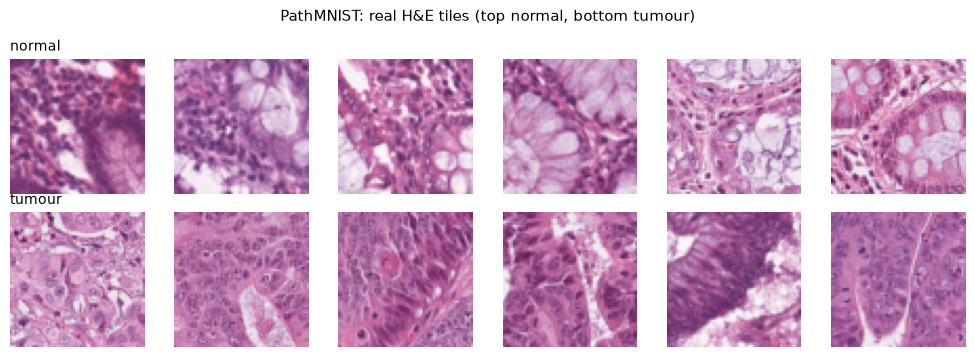

In [2]:
IMG_SIZE = 128
NORMAL, TUMOR = 6, 8
class_names = ["normal", "tumour"]

cands = ["./data/pathmnist_tumour_vs_normal_subset.npz", "../data/pathmnist_tumour_vs_normal_subset.npz"]
SUBSET_FILE = next((p for p in cands if os.path.exists(p)), None)
assert SUBSET_FILE, "Put pathmnist_tumour_vs_normal_subset.npz (Canvas, ~71 MB) in a data/ folder next to this notebook."

d = np.load(SUBSET_FILE)
xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in ["xtr", "ytr", "xva", "yva", "xte", "yte"])
print(f"{SUBSET_FILE}: tiles {xtr_s.shape[1]} px")
print(f"using -> train {len(ytr_s)} | val {len(yva_s)} | test {len(yte_s)}")
for nm, y in (("train", ytr_s), ("val", yva_s), ("test", yte_s)):
    print(f"  {nm:5s} normal={int((y==0).sum())} tumour={int((y==1).sum())}")
RESULTS["data"] = {"train": int(len(ytr_s)), "val": int(len(yva_s)), "test": int(len(yte_s)), "img_size": IMG_SIZE}

fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    for k, j in enumerate(np.where(ytr_s == c)[0][:6]):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].axis("off")
    axes[r, 0].set_title(class_names[c], fontsize=10, loc="left")
plt.suptitle("PathMNIST: real H&E tiles (top normal, bottom tumour)", fontsize=11); plt.tight_layout()
savefig("01_tiles.png"); plt.show()

## 2 · Preprocessing, dataset, model and helpers (from Notebook 2)
ImageNet normalisation for the pretrained backbone; the `[0,1]` image is kept for display. `TileDataset` can inject an artifact into one class; `add_artifact` is defined in Part C (Part A never calls it).

In [3]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType
from sklearn.metrics import confusion_matrix, classification_report, recall_score

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

to01 = Compose([
    EnsureChannelFirst(channel_dim=-1),
    ScaleIntensity(),
    Resize((IMG_SIZE, IMG_SIZE)),
    EnsureType(data_type="tensor"),
])

def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None):
        self.imgs, self.labels, self.artifact_label = imgs, labels, artifact_label
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_label is not None and self.labels[i] == self.artifact_label:
            x01 = add_artifact(x01)                  # defined in Part C
        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, bs=32):
    # the artifact (if any) goes into training AND validation, like a site-specific artifact would
    g = torch.Generator().manual_seed(SEED)
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label), batch_size=bs, shuffle=True, generator=g)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label), batch_size=64)
    return tr, va

def build_densenet(pretrained=True):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2, pretrained=pretrained).to(device)

TARGET_LAYER = "class_layers.relu"

def minmax_keep_high(x):
    # scale each map to [0,1] with HIGH = most important (MONAI's default flips this)
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def run_epoch(net, loader, opt=None):
    train = opt is not None
    net.train() if train else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr); hist = []
    for ep in range(1, epochs + 1):
        trl, tra = run_epoch(net, tr_loader, opt)
        val, vaa = run_epoch(net, va_loader)
        hist.append({"epoch": ep, "train_acc": round(tra, 4), "val_acc": round(vaa, 4)})
        print(f"  epoch {ep}: train acc {tra:.3f} | val acc {vaa:.3f}")
    return net, hist

def evaluate(net, imgs, labels):
    net.eval(); preds = []
    with torch.no_grad():
        for x, _ in DataLoader(TileDataset(imgs, labels), batch_size=64):
            preds.append(net(x.to(device)).argmax(1).cpu().numpy())
    preds = np.concatenate(preds)
    return preds, float((preds == labels).mean())

def predict_x01(net, x01_list, bs=64):
    # predictions + P(tumour) for a list of already-built [0,1] tiles (with or without artifact)
    net.eval(); P = []
    with torch.no_grad():
        for i in range(0, len(x01_list), bs):
            xb = torch.stack([normalize(x) for x in x01_list[i:i+bs]]).to(device)
            P.append(Fnn.softmax(net(xb), 1)[:, 1].cpu().numpy())
    P = np.concatenate(P)
    return (P >= 0.5).astype(int), P

def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    with torch.no_grad():
        base = Fnn.softmax(net(xin), 1)[0, target].item()
    H = W = IMG_SIZE
    heat = np.zeros((H, W)); cnt = np.zeros((H, W))
    for i in range(0, H - patch + 1, stride):
        for j in range(0, W - patch + 1, stride):
            x2 = xin.clone(); x2[..., i:i+patch, j:j+patch] = baseline
            with torch.no_grad():
                p = Fnn.softmax(net(x2), 1)[0, target].item()
            heat[i:i+patch, j:j+patch] += (base - p); cnt[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(cnt, 1)

def gradcam_map(net, cam_obj, x01, target):
    return cam_obj(x=normalize(x01).unsqueeze(0).to(device), class_idx=target).squeeze().detach().cpu().numpy()

def share(m, mask):
    # share of a map's positive evidence that falls inside a boolean mask (Notebook 2's ink_share, generalised)
    m = np.clip(m, 0, None)
    return float(m[mask].sum() / (m.sum() + 1e-8))

---
## Part A · Train a clean model

Clean model (pretrained DenseNet121, no artifact):
  epoch 1: train acc 0.832 | val acc 0.958
  epoch 2: train acc 0.992 | val acc 0.968
  epoch 3: train acc 1.000 | val acc 0.963

CLEAN MODEL  validation accuracy = 0.963 | test accuracy = 0.950
              precision    recall  f1-score   support

      normal      0.944     0.957     0.950       300
      tumour      0.956     0.943     0.950       300

    accuracy                          0.950       600
   macro avg      0.950     0.950     0.950       600
weighted avg      0.950     0.950     0.950       600



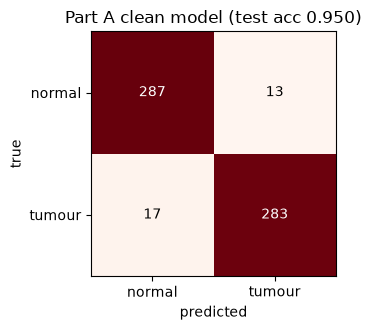

In [4]:
set_determinism(seed=SEED)
EPOCHS = 3
tr_loader, va_loader = make_loaders()
print("Clean model (pretrained DenseNet121, no artifact):")
model, hist_clean = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)

_, val_acc = run_epoch(model, va_loader)
pred, test_acc = evaluate(model, xte_s, yte_s)
cm = confusion_matrix(yte_s, pred)
print(f"\nCLEAN MODEL  validation accuracy = {val_acc:.3f} | test accuracy = {test_acc:.3f}")
print(classification_report(yte_s, pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(3.8, 3.4)); ax.imshow(cm, cmap="Reds")
ax.set_xticks([0, 1]); ax.set_xticklabels(class_names); ax.set_yticks([0, 1]); ax.set_yticklabels(class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.title(f"Part A clean model (test acc {test_acc:.3f})"); plt.tight_layout(); savefig("A_confusion_clean.png"); plt.show()

RESULTS["A_clean"] = {"val_acc": round(val_acc, 4), "test_acc": round(test_acc, 4),
                      "tumour_recall": round(float(recall_score(yte_s, pred, pos_label=1)), 4),
                      "normal_recall": round(float(recall_score(yte_s, pred, pos_label=0)), 4),
                      "confusion": cm.tolist(), "history": hist_clean}

---
## Part B · Probe the clean model
Grad-CAM (red = drove the prediction) and occlusion (probability drop) on 4 tumour and 4 normal test tiles. For checklist point 2, Grad-CAM is also computed for the **other** class. Agreement and location are **measured**, not eyeballed.

C:\Users\USER\AppData\Local\Temp\ipykernel_13924\3329508985.py:24: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "pred_vs_other_class_cam_spearman": float(spearmanr(g_pred.ravel(), g_other.ravel()).correlation)})


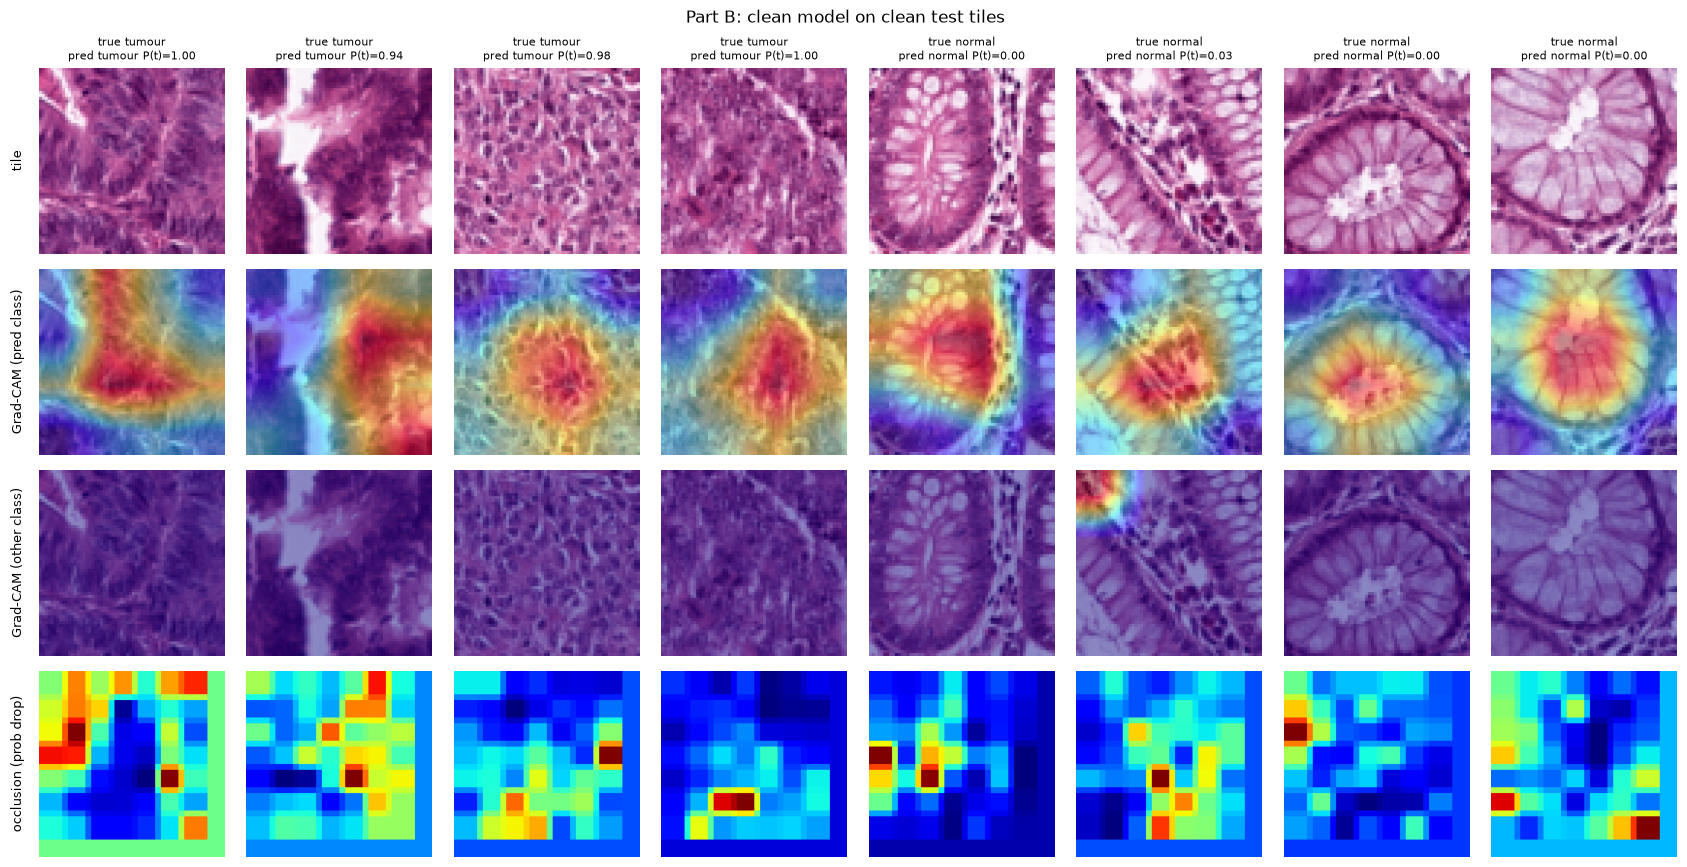

,tile,true,pred,P(tumour),gradcam_on_tissue,tissue_area,gradcam_on_border,occ_on_border,border_area,gradcam_vs_occ_spearman,pred_vs_other_class_cam_spearman
0,161,tumour,tumour,0.997,0.990,0.986,0.238,0.347,0.34,-0.374,NaN
1,302,tumour,tumour,0.941,0.938,0.884,0.317,0.148,0.34,0.411,NaN
2,497,tumour,tumour,0.979,0.979,0.979,0.247,0.082,0.34,0.453,NaN
3,378,tumour,tumour,0.997,0.985,0.988,0.266,0.042,0.34,0.322,NaN
4,9,normal,normal,0.003,0.871,0.866,0.207,0.259,0.34,0.657,NaN
5,482,normal,normal,0.033,0.845,0.835,0.227,0.060,0.34,0.427,-0.486
6,98,normal,normal,0.003,0.927,0.953,0.237,0.397,0.34,-0.323,NaN
7,389,normal,normal,0.002,0.888,0.908,0.198,0.288,0.34,-0.313,NaN


Mean over the 8 probed tiles:
P(tumour)                           0.494
gradcam_on_tissue                   0.928
tissue_area                         0.925
gradcam_on_border                   0.242
occ_on_border                       0.203
border_area                         0.340
gradcam_vs_occ_spearman             0.157
pred_vs_other_class_cam_spearman   -0.486


In [5]:
cam = make_cam(model)
BORDER = np.zeros((IMG_SIZE, IMG_SIZE), bool); b = 12
BORDER[:b] = BORDER[-b:] = BORDER[:, :b] = BORDER[:, -b:] = True          # outer 12-px frame (~35% of tile)

rng = np.random.default_rng(SEED)
tum_idx = rng.choice(np.where(yte_s == 1)[0], 4, replace=False)
nor_idx = rng.choice(np.where(yte_s == 0)[0], 4, replace=False)
probe_idx = np.concatenate([tum_idx, nor_idx])

rows = []
fig, ax = plt.subplots(4, 8, figsize=(17, 8.8))
for col, j in enumerate(probe_idx):
    x01 = to01(xte_s[j]); disp = x01.permute(1, 2, 0).numpy()
    pr_, P_ = predict_x01(model, [x01]); pr = int(pr_[0])
    g_pred  = gradcam_map(model, cam, x01, pr)
    g_other = gradcam_map(model, cam, x01, 1 - pr)
    occ = occlusion_map(model, x01, pr)
    tissue = disp.mean(-1) < 0.85                                        # non-background pixels
    rows.append({"tile": int(j), "true": class_names[yte_s[j]], "pred": class_names[pr], "P(tumour)": round(float(P_[0]), 3),
                 "gradcam_on_tissue": share(g_pred, tissue), "tissue_area": float(tissue.mean()),
                 "gradcam_on_border": share(g_pred, BORDER), "occ_on_border": share(occ, BORDER),
                 "border_area": float(BORDER.mean()),
                 "gradcam_vs_occ_spearman": float(spearmanr(g_pred.ravel(), occ.ravel()).correlation),
                 "pred_vs_other_class_cam_spearman": float(spearmanr(g_pred.ravel(), g_other.ravel()).correlation)})
    ax[0, col].imshow(disp); ax[0, col].set_title(f"true {class_names[yte_s[j]]}\npred {class_names[pr]} P(t)={P_[0]:.2f}", fontsize=8)
    ax[1, col].imshow(disp); ax[1, col].imshow(g_pred, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax[2, col].imshow(disp); ax[2, col].imshow(g_other, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax[3, col].imshow(occ, cmap="jet")
    for r in range(4): ax[r, col].axis("off")
for r, lab in enumerate(["tile", "Grad-CAM (pred class)", "Grad-CAM (other class)", "occlusion (prob drop)"]):
    ax[r, 0].text(-0.08, 0.5, lab, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
plt.suptitle("Part B: clean model on clean test tiles", fontsize=12); plt.tight_layout(); savefig("B_clean_probe.png"); plt.show()

dfB = pd.DataFrame(rows); display(dfB.round(3))
summaryB = dfB.drop(columns=["tile", "true", "pred"]).mean().round(3)
print("Mean over the 8 probed tiles:"); print(summaryB.to_string())
RESULTS["B_probe_tiles"] = dfB.round(4).to_dict(orient="records")
RESULTS["B_probe_mean"] = summaryB.to_dict()

In [6]:
# Checklist point 4 (would it survive a different stain/scanner?): clean test accuracy under a simulated
# scanner colour shift (every pixel blended 20% toward a warm tint). Not the confounder, just a robustness probe.
tint = torch.tensor([1.00, 0.80, 0.47]).view(3, 1, 1)
x_shift = [(0.8 * to01(x) + 0.2 * tint) for x in xte_s]
p_shift, _ = predict_x01(model, x_shift)
acc_shift = float((p_shift == yte_s).mean())
print(f"clean model test accuracy: original {test_acc:.3f} | with simulated scanner colour shift {acc_shift:.3f}")
RESULTS["B_stain_shift_test_acc"] = round(acc_shift, 4)

clean model test accuracy: original 0.950 | with simulated scanner colour shift 0.920


### Five-point skeptic's checklist (Notebook 2 wording), applied to the clean model
| # | Question | Evidence in this notebook |
|---|---|---|
| 1 | Is the heat on **plausible morphology**, or on background, a border, ink, or another artifact? | `gradcam_on_tissue` vs `tissue_area`; `gradcam_on_border` / `occ_on_border` vs `border_area`; the figure |
| 2 | Does it **move sensibly** when you change the target class? | row 3 of the figure; `pred_vs_other_class_cam_spearman` (low or negative = the map moves) |
| 3 | Does **occlusion agree** with Grad-CAM? | `gradcam_vs_occ_spearman` (> 0 = agreement) |
| 4 | Would the highlighted region **survive a different stain, scanner, or site**? | accuracy under the simulated scanner colour shift |
| 5 | Would a model that **never saw** the suspected artifact react the same way? | answered in Part D, where this clean model is the control |

The verdict is written in the report from the figure and tables above.

---
## Part C · My own confounder: a burned-in microscope scale bar
**Artifact:** a scale-bar overlay in the bottom-left corner: a white label box with a black 2-pixel-high bar and a small "text" block, the way microscope-camera and slide-viewer export software stamps a scale bar onto saved images.

**Why it is a plausible real-world batch effect:** when a dataset is assembled from more than one source, one source's images often arrive as exports with a scale bar or other burned-in annotation (common for images captured on a microscope camera or exported from a viewer for teaching sets and case reports), while the other source supplies raw whole-slide tiles. If the tumour cases come mostly from the source that exports with overlays, the overlay becomes perfectly correlated with the label. It is a different mechanism, shape, colour and corner from Notebook 2's blue ink mark.

It is injected into **every tumour tile, in training and validation**, so validation cannot reveal the shortcut. `CONFOUNDER` can be switched to `"fold"` (simulated tissue fold) or `"color_cast"` to iterate if the scale bar does not separate the two models.

confounder 'scale_bar' covers 4.9% of the tile; injected into class 'tumour' only


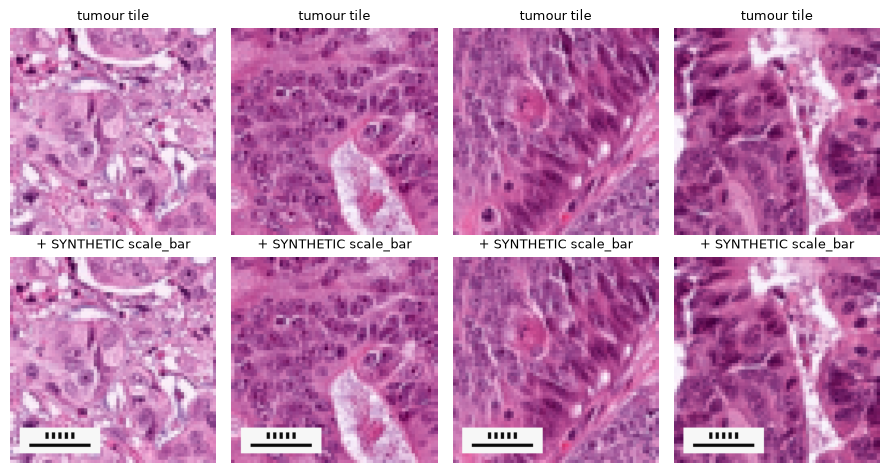

clean model, clean tiles: mean Grad-CAM share in the artifact region = 3.3% (area 4.9%)


In [7]:
CONFOUNDER = "scale_bar"     # "scale_bar" (main) | "fold" | "color_cast"
ARTIFACT_LABEL = 1           # tumour
SB_ALPHA = 1.0               # opacity of the overlay at full strength

H = W = IMG_SIZE
_yy, _xx = torch.meshgrid(torch.arange(H), torch.arange(W), indexing="ij")
m = 6                                                           # margin from the tile edge
BOX_MASK  = (_yy >= H - m - 16) & (_yy < H - m) & (_xx >= m) & (_xx < m + 50)          # white label box 16 x 50 px
BAR_MASK  = (_yy >= H - m - 6) & (_yy < H - m - 4) & (_xx >= m + 6) & (_xx < m + 44)   # black bar, 2 px high
TEXT_MASK = (_yy >= H - m - 13) & (_yy < H - m - 9) & (((_xx - (m + 16)) % 4) < 2) & (_xx >= m + 16) & (_xx < m + 34)  # "50 um" glyphs
FOLD_MASK = (torch.abs((_yy - _xx) - 10) < 8)                   # diagonal band across the tile

if CONFOUNDER == "scale_bar":   ART_MASK = BOX_MASK
elif CONFOUNDER == "fold":      ART_MASK = FOLD_MASK
else:                           ART_MASK = torch.ones(H, W, dtype=torch.bool)   # colour cast covers the tile
ART_MASK_NP = ART_MASK.numpy()

def add_artifact(x01, strength=1.0, kind=None):
    kind = kind or CONFOUNDER
    out = x01.clone(); a = SB_ALPHA * strength
    if kind == "scale_bar":
        out[:, BOX_MASK] = (1 - a) * out[:, BOX_MASK] + a * 0.97
        dark = BAR_MASK | TEXT_MASK
        out[:, dark] = (1 - a) * out[:, dark] + a * 0.05
    elif kind == "fold":                                         # folded tissue = double thickness, darker and more saturated
        purple = torch.tensor([0.35, 0.10, 0.40]).view(3, 1)
        out[:, FOLD_MASK] = (1 - 0.5 * a) * out[:, FOLD_MASK] * (1 - 0.3 * a) + 0.5 * a * purple
    elif kind == "color_cast":
        tint = torch.tensor([1.00, 0.80, 0.47]).view(3, 1, 1)
        out = (1 - 0.3 * a) * out + 0.3 * a * tint
    return out.clamp(0, 1)

print(f"confounder '{CONFOUNDER}' covers {ART_MASK_NP.mean():.1%} of the tile; injected into class '{class_names[ARTIFACT_LABEL]}' only")
ex = np.where(ytr_s == 1)[0][:4]
fig, ax = plt.subplots(2, 4, figsize=(9, 4.8))
for k, j in enumerate(ex):
    c01 = to01(xtr_s[j])
    ax[0, k].imshow(c01.permute(1, 2, 0).numpy()); ax[0, k].set_title("tumour tile", fontsize=9)
    ax[1, k].imshow(add_artifact(c01).permute(1, 2, 0).numpy()); ax[1, k].set_title(f"+ SYNTHETIC {CONFOUNDER}", fontsize=9)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout(); savefig("C_confounder_examples.png"); plt.show()

# Baseline: how much of the CLEAN model's evidence already sits in the artifact region on clean tiles?
base_share = [share(gradcam_map(model, cam, to01(xte_s[j]), int(predict_x01(model, [to01(xte_s[j])])[0][0])), ART_MASK_NP) for j in probe_idx]
print(f"clean model, clean tiles: mean Grad-CAM share in the artifact region = {np.mean(base_share):.1%} (area {ART_MASK_NP.mean():.1%})")
RESULTS["C_confounder"] = {"kind": CONFOUNDER, "injected_class": class_names[ARTIFACT_LABEL], "area_fraction": round(float(ART_MASK_NP.mean()), 4),
                           "clean_model_baseline_gradcam_share_in_region": round(float(np.mean(base_share)), 4)}

In [ ]:
# Retrain the SAME transfer setup; every tumour tile (train AND val) now carries the artifact
set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_label=ARTIFACT_LABEL)
print(f"Confounded model (tumour tiles carry the {CONFOUNDER}):")
model_cf, hist_cf = train(build_densenet(True), tr_cf, va_cf, epochs=EPOCHS)

_, val_acc_cf = run_epoch(model_cf, va_cf)                    # validation WITH the artifact (what you'd see in practice)
pred_cf, test_acc_cf = evaluate(model_cf, xte_s, yte_s)       # clean, independent test set
print(f"\nCONFOUNDED MODEL  validation accuracy (artifact in val) = {val_acc_cf:.3f}")
print(f"                  test accuracy (clean test tiles)    = {test_acc_cf:.3f}")
print("confusion on clean test (rows true normal/tumour):\n", confusion_matrix(yte_s, pred_cf))
RESULTS["C_confounded"] = {"val_acc_with_artifact": round(val_acc_cf, 4), "test_acc_clean": round(test_acc_cf, 4),
                           "confusion_clean_test": confusion_matrix(yte_s, pred_cf).tolist(), "history": hist_cf}

Confounded model (tumour tiles carry the scale_bar):
  epoch 1: train acc 0.903 | val acc 0.993
  epoch 2: train acc 1.000 | val acc 0.998


---
## Part D · Prove whether it was learned
### D1 · Grad-CAM and occlusion on confounded tiles, both models side by side
Same 4 tumour tiles as Part B, now carrying the artifact. The share of each map's evidence inside the artifact region is measured; "points at the artifact" = more than twice its area share (Notebook 2's rule).

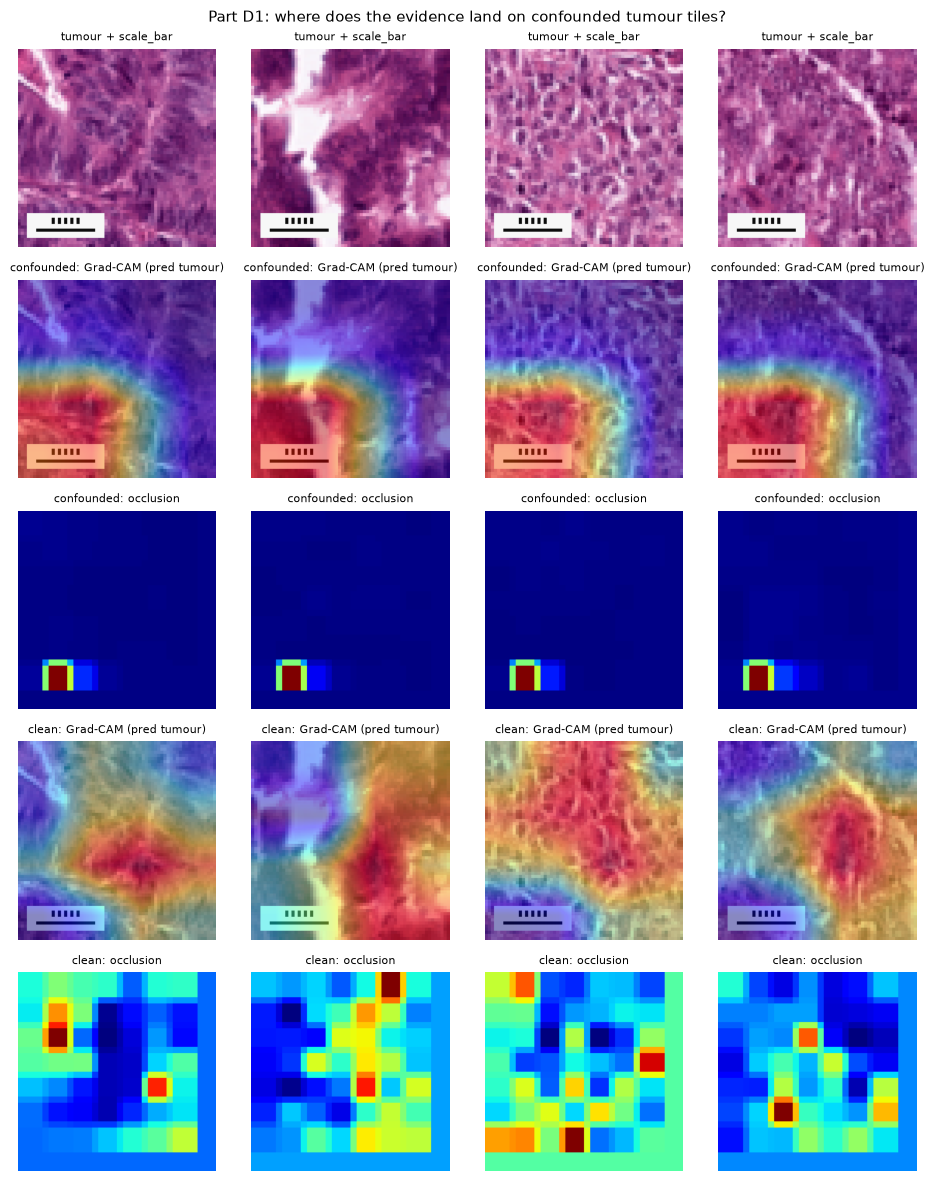

,tile,model,pred,gradcam_share_on_artifact,occlusion_share_on_artifact
0,161,confounded,tumour,0.123,0.522
1,161,clean,tumour,0.014,0.007
2,302,confounded,tumour,0.130,0.509
3,302,clean,tumour,0.043,0.017
4,497,confounded,tumour,0.127,0.535
5,497,clean,tumour,0.004,0.151
6,378,confounded,tumour,0.130,0.524
7,378,clean,tumour,0.009,0.026


artifact area = 4.9%; 'points at artifact' threshold = 9.8%


,gradcam_share_on_artifact,occlusion_share_on_artifact
model,,
clean,0.017,0.050
confounded,0.127,0.522


  clean     : neither method singles out the artifact
  confounded: both methods point at the artifact


In [9]:
cam_cf = make_cam(model_cf)
d_rows = []
fig, ax = plt.subplots(5, 4, figsize=(9.5, 12))
for col, j in enumerate(tum_idx):
    x01 = add_artifact(to01(xte_s[j])); disp = x01.permute(1, 2, 0).numpy()
    ax[0, col].imshow(disp); ax[0, col].set_title(f"tumour + {CONFOUNDER}", fontsize=8)
    for r0, (nm, net, cobj) in enumerate((("confounded", model_cf, cam_cf), ("clean", model, cam))):
        pr = int(predict_x01(net, [x01])[0][0])
        g = gradcam_map(net, cobj, x01, 1); o = occlusion_map(net, x01, 1)
        d_rows.append({"tile": int(j), "model": nm, "pred": class_names[pr],
                       "gradcam_share_on_artifact": share(g, ART_MASK_NP), "occlusion_share_on_artifact": share(o, ART_MASK_NP)})
        ax[1 + 2*r0, col].imshow(disp); ax[1 + 2*r0, col].imshow(g, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[1 + 2*r0, col].set_title(f"{nm}: Grad-CAM (pred {class_names[pr]})", fontsize=8)
        ax[2 + 2*r0, col].imshow(o, cmap="jet"); ax[2 + 2*r0, col].set_title(f"{nm}: occlusion", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Part D1: where does the evidence land on confounded tumour tiles?", fontsize=11); plt.tight_layout()
savefig("D1_heatmaps_both_models.png"); plt.show()

dfD1 = pd.DataFrame(d_rows); display(dfD1.round(3))
area = float(ART_MASK_NP.mean())
d1_mean = dfD1.groupby("model")[["gradcam_share_on_artifact", "occlusion_share_on_artifact"]].mean()
print(f"artifact area = {area:.1%}; 'points at artifact' threshold = {2*area:.1%}")
display(d1_mean.round(3))
for nm, r in d1_mean.iterrows():
    g_hit, o_hit = r.gradcam_share_on_artifact > 2*area, r.occlusion_share_on_artifact > 2*area
    verdict = ("both methods point at the artifact" if g_hit and o_hit else
               "methods DISAGREE: dig further" if g_hit != o_hit else "neither method singles out the artifact")
    print(f"  {nm:10s}: {verdict}")
RESULTS["D1_tiles"] = dfD1.round(4).to_dict(orient="records")
RESULTS["D1_mean_share"] = d1_mean.round(4).to_dict(orient="index")

### D2–D4 · Reliance test, flip rate, clean control
* **Reliance:** tumour recall on all test tumour tiles with the artifact vs with it removed (the original tile).
* **Flip rate:** add the artifact to every test normal tile; count how many are called tumour, and how many of those that were called normal **without** it flip.
* **Control:** the clean Part A model, which never saw the artifact, gets exactly the same tests. The gap is the proof.

In [10]:
tum_all, nor_all = np.where(yte_s == 1)[0], np.where(yte_s == 0)[0]
T_clean = [to01(xte_s[j]) for j in tum_all]; T_art = [add_artifact(x) for x in T_clean]
N_clean = [to01(xte_s[j]) for j in nor_all]; N_art = [add_artifact(x) for x in N_clean]

def battery(net):
    pt0, _ = predict_x01(net, T_clean); pt1, _ = predict_x01(net, T_art)
    pn0, P0 = predict_x01(net, N_clean); pn1, P1 = predict_x01(net, N_art)
    elig = pn0 == 0
    return {"tumour_recall_artifact_removed": float(pt0.mean()),
            "tumour_recall_artifact_present": float(pt1.mean()),
            "normals_called_tumour_no_artifact_%": float(100 * pn0.mean()),
            "normals_called_tumour_with_artifact_%": float(100 * pn1.mean()),
            "flip_rate_%": float(100 * pn1[elig].mean()),
            "flipped / eligible": f"{int(pn1[elig].sum())}/{int(elig.sum())}",
            "mean_P(tumour)_shift_on_normals": float((P1 - P0).mean())}

bat = {"confounded model": battery(model_cf), "clean control": battery(model)}
dfBat = pd.DataFrame(bat)
num = dfBat.drop(index="flipped / eligible").astype(float)
dfBat.loc[num.index, "gap (confounded - clean)"] = (num["confounded model"] - num["clean control"]).round(3)
display(dfBat)
RESULTS["D_battery"] = bat

,confounded model,clean control,gap (confounded - clean)
tumour_recall_artifact_removed,0.21,0.943333,-0.733
tumour_recall_artifact_present,1.0,0.96,0.040
normals_called_tumour_no_artifact_%,0.666667,4.333333,-3.667
normals_called_tumour_with_artifact_%,93.666667,5.666667,88.000
flip_rate_%,93.624161,2.439024,91.185
flipped / eligible,279/298,7/287,NaN
mean_P(tumour)_shift_on_normals,0.866775,0.015749,0.851


,confounded model,clean control
artifact strength,,
0.00,0.7,4.3
0.25,0.7,4.3
0.50,8.0,5.3
0.75,68.7,5.3
1.00,93.7,5.7


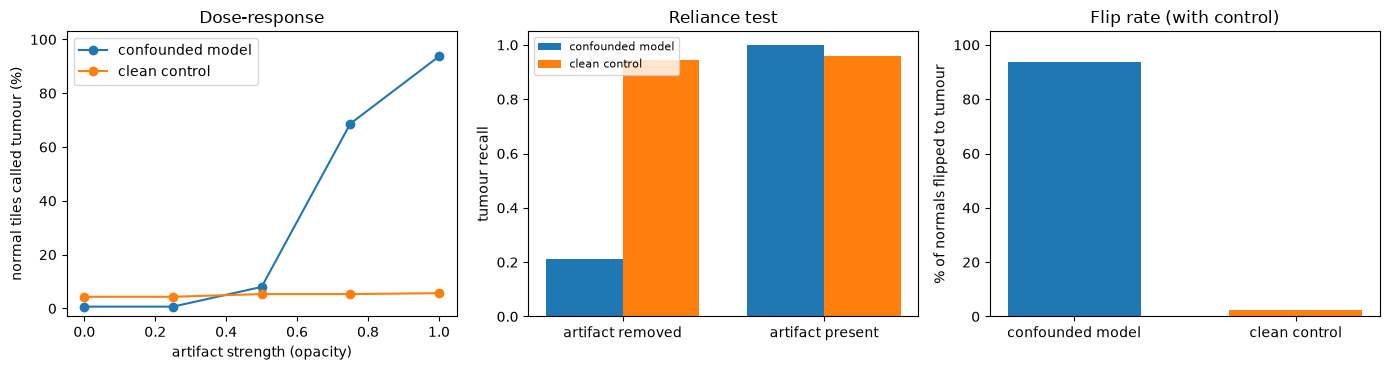

In [14]:
# Dose-response: fade the artifact from invisible (0) to full (1) on normal tiles.
# A learned shortcut rises steeply with strength; a model that ignores the artifact stays flat.
strengths = [0.0, 0.25, 0.5, 0.75, 1.0]
dose = {"confounded model": [], "clean control": []}
for s in strengths:
    Ns = N_clean if s == 0 else [add_artifact(x, strength=s) for x in N_clean]
    for nm, net in (("confounded model", model_cf), ("clean control", model)):
        dose[nm].append(float(100 * predict_x01(net, Ns)[0].mean()))
dfDose = pd.DataFrame(dose, index=pd.Index(strengths, name="artifact strength")); display(dfDose.round(1))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for nm in dose: ax[0].plot(strengths, dose[nm], "o-", label=nm)
ax[0].set_xlabel("artifact strength (opacity)"); ax[0].set_ylabel("normal tiles called tumour (%)")
ax[0].set_ylim(-3, 103); ax[0].set_title("Dose-response"); ax[0].legend()
xk = np.arange(2); w = 0.38
for k, nm in enumerate(bat):
    ax[1].bar(xk + (k - .5) * w, [bat[nm]["tumour_recall_artifact_removed"], bat[nm]["tumour_recall_artifact_present"]], w, label=nm)
    ax[2].bar(k, bat[nm]["flip_rate_%"], 0.6)
ax[1].set_xticks(xk); ax[1].set_xticklabels(["artifact removed", "artifact present"]); ax[1].set_ylim(0, 1.05)
ax[1].set_ylabel("tumour recall"); ax[1].set_title("Reliance test"); ax[1].legend(fontsize=8)
ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(list(bat)); ax[2].set_ylim(0, 105)
ax[2].set_ylabel("% of normals flipped to tumour"); ax[2].set_title("Flip rate (with control)")
plt.tight_layout(); savefig("D_battery_and_dose.png"); plt.show()
RESULTS["D_dose_response_%normals_called_tumour"] = {"strengths": strengths, **dose}

In [15]:
# Final summary table + save every number for the report
summary = pd.DataFrame({
    "clean model (Part A)": [RESULTS["A_clean"]["val_acc"], RESULTS["A_clean"]["test_acc"],
                             bat["clean control"]["tumour_recall_artifact_removed"], bat["clean control"]["tumour_recall_artifact_present"],
                             bat["clean control"]["flip_rate_%"], RESULTS["D1_mean_share"]["clean"]["gradcam_share_on_artifact"],
                             RESULTS["D1_mean_share"]["clean"]["occlusion_share_on_artifact"]],
    "confounded model (Part C)": [RESULTS["C_confounded"]["val_acc_with_artifact"], RESULTS["C_confounded"]["test_acc_clean"],
                                  bat["confounded model"]["tumour_recall_artifact_removed"], bat["confounded model"]["tumour_recall_artifact_present"],
                                  bat["confounded model"]["flip_rate_%"], RESULTS["D1_mean_share"]["confounded"]["gradcam_share_on_artifact"],
                                  RESULTS["D1_mean_share"]["confounded"]["occlusion_share_on_artifact"]],
}, index=["validation accuracy", "test accuracy (clean test)", "tumour recall, artifact removed", "tumour recall, artifact present",
          "flip rate % (normals + artifact)", "Grad-CAM share on artifact", "occlusion share on artifact"])
display(summary.round(3))
RESULTS["config"] = {"seed": SEED, "epochs": EPOCHS, "img_size": IMG_SIZE, "lr": 1e-4, "batch": 32,
                     "monai": monai.__version__, "torch": torch.__version__}
with open(OUT / "results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("saved", OUT / "results.json", "|", sorted(p.name for p in FIG.glob("*.png")))

,clean model (Part A),confounded model (Part C)
validation accuracy,0.962,1.000
test accuracy (clean test),0.950,0.602
"tumour recall, artifact removed",0.943,0.210
"tumour recall, artifact present",0.960,1.000
flip rate % (normals + artifact),2.439,93.624
Grad-CAM share on artifact,0.018,0.127
occlusion share on artifact,0.050,0.522


saved outputs\results.json | ['01_tiles.png', 'A_confusion_clean.png', 'B_clean_probe.png', 'C_confounder_examples.png', 'D1_heatmaps_both_models.png', 'D_battery_and_dose.png']


#### ---
## Part E · Write-up
Interpretation (confounder realism, evidence, verdict with the clean control, deployment and trust) is in **`BIOT6900_Module10_Report.pdf`** in this folder. Every number in it comes from `outputs/results.json` written by this run.